# Supplementary Fig S2 · Breast: niches, block programmes and gene-list queries

The old Fig 6 (`_backup_2026-11-01/F6_breast.ipynb`) without its panels D (the held-out query and its nearest tiles,
now main Fig 3C) and E (the five signatures' gene-list queries; dropped 1 Nov).

* **Needs:** `R6_breast_programs` (writes `results/breast_programs/`).
* **Writes:** `figures/figS2_breast/panels/{A..C}.{pdf,png}` and `figures/figS2_breast/figS5_breast.{pdf,png}`.

Panels A–C come from the whole-section build (`full`: every tile indexed).
Niches are numbered from 1 (niche k of the build is "Niche k + 1").

| Panel | Content |
|---|---|
| A | Cells coloured by their tile's niche; log2 enrichment of the 19 annotated cell types per niche, and the section's fractions |
| B | r of ACTA2 with its block partners in each niche (○ = in ACTA2's block there) |
| C | Niche-mean correlation of the chosen niche (the most blocks both co-varying and enriched; ties go to more tiles), in its gene order with its blocks outlined; the largest other niche in the same order; the key of the co-varying blocks |

Renumbered S5 → S2 on 3 Nov (supplement reorganised; cited from the Results overview); unchanged otherwise.

In [1]:
import json
import re
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.patches import Patch, Rectangle

import style as ps
from sections import CLASSES

FIG = "figS2_breast"
RES = ROOT / "results" / "breast_programs"
S0, FULL = RES / "seed0", RES / "full"
NO_TILE = "#E3E3E3"  # cells of the low-density tiles that tiling drops
MAP_W = 60.0
CORR_LIM, ACTA2_LIM = 0.4, 0.6

blocks = pd.read_csv(FULL / "blocks.csv")
LAYOUT = json.loads((FULL / "layout.json").read_text())
GENES = np.array(LAYOUT["genes"])
NICHES = sorted(blocks.niche.unique())
NICHE_COLORS = ps.niche_palette(len(NICHES))
_b = blocks.assign(both=blocks.covarying & blocks.enriched).groupby("niche").agg(both=("both", "sum"),
                                                                                tiles=("n_tiles", "first"))
MAIN = int(_b.sort_values(["both", "tiles"], ascending=False).index[0])
CONTRAST = int(_b.drop(MAIN).sort_values("tiles", ascending=False).index[0])
print(f"chosen niche {MAIN + 1}, contrast niche {CONTRAST + 1}")


# ---- placement inside a panel (a Figure alone, a SubFigure from ps.place on the page): mm from its top-left corner
class At:
    def __init__(self, fig):
        self.fig, self.x0, self.y0 = fig, 0.0, 0.0
        self.W, self.H = ps.size_mm(fig)


def box(P, x, y, w, h, left=0.0, bottom=0.0, right=0.0, top=0.0, **kw):
    """Axes of the w x h mm box at (x, y) of the panel, inset by the margins (mm)."""
    x, y = P.x0 + x, P.y0 + y
    return P.fig.add_axes([(x + left) / P.W, 1 - (y + h - bottom) / P.H, (w - left - right) / P.W,
                           (h - top - bottom) / P.H], **kw)


def text(P, x, y, s, size=ps.LABEL_PT, ha="left", w=0.0, **kw):
    """Text with its top at y; ha="center" centres it on a w mm wide box at x."""
    x, y = P.x0 + x + (w / 2 if ha == "center" else 0), P.y0 + y
    P.fig.text(x / P.W, 1 - y / P.H, s, fontsize=size, ha=ha, va="top", **kw)


def hbar(P, x, y, w, h, cmap, vmin, vmax, ticks):
    """A horizontal colourbar as the old colorbar atoms (bar 2.5 mm, ticks below)."""
    ax = box(P, x, y, w, h, left=2.0, right=2.0, bottom=h - 3.0, top=0.5)
    cb = P.fig.colorbar(ScalarMappable(Normalize(vmin, vmax), cmap), cax=ax, orientation="horizontal", ticks=ticks)
    cb.outline.set_linewidth(0.5)


def legend(P, x, y, w, h, handles, ncol, **kw):
    x, y = P.x0 + x + w / 2, P.y0 + y + h / 2
    P.fig.legend(handles=handles, ncol=ncol, loc="center", bbox_to_anchor=(x / P.W, 1 - y / P.H), **kw)


def spatial(ax, x0, x1, y0, y1):
    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)  # image orientation
    ax.set_aspect("equal")
    ax.axis("off")


def heat_axes(ax):
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

chosen niche 1, contrast niche 2


## A · Niches and their cell types

figures/figS2_breast/panels/A.pdf/.png: 124 x 67 mm, 1.2 / 1.4 MB


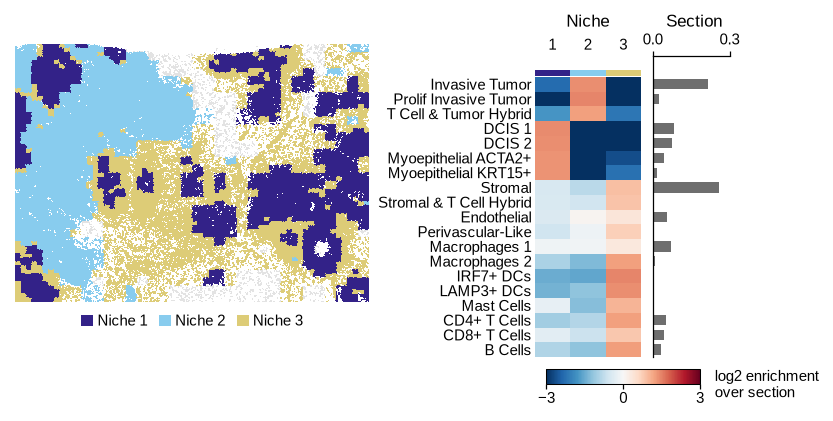

In [2]:
A_W, A_H = 124.0, 67.0


def panel_a(P):
    z = np.load(FULL / "cells_niche.npz")
    xy, niche = z["xy"], z["niche"]
    (x0, y0), (x1, y1) = xy.min(0), xy.max(0)
    ax = box(P, 0, 5, MAP_W, MAP_W * (y1 - y0) / (x1 - x0))
    col = np.array([NO_TILE] + NICHE_COLORS)[niche + 1]
    order = np.argsort(niche >= 0, kind="stable")  # cells without a tile underneath
    ax.scatter(xy[order, 0], xy[order, 1], s=0.05, c=col[order], lw=0, rasterized=True, antialiased=False)
    spatial(ax, x0, x1, y0, y1)
    legend(P, 0, 50, MAP_W, 4, [Patch(fc=c, ec="none", label=f"Niche {k + 1}") for k, c in zip(NICHES, NICHE_COLORS)],
           ncol=len(NICHES), handlelength=0.8, columnspacing=0.8, handletextpad=0.3)

    t = pd.read_csv(FULL / "niche_types.csv")
    types = [m for _, _, members in CLASSES for m in members]
    F = t.pivot(index="type", columns="niche", values="frac").loc[types, NICHES].to_numpy()
    sec = t.groupby("type")["section_frac"].first().loc[types].to_numpy()
    with np.errstate(divide="ignore"):
        E = np.clip(np.log2(F / sec[:, None]), -3, 3)
    ax = box(P, 62, 3, 62, 56, left=26.0, bottom=1.0, right=18.0, top=4.0)
    ax.imshow(E, cmap=ps.DIVERGING, vmin=-3, vmax=3, aspect="auto", interpolation="nearest")
    ax.set_yticks(range(len(types)))
    ax.set_yticklabels([s.replace("_", " ").replace("Myoepi ", "Myoepithelial ") for s in types])
    ax.set_xticks(range(len(NICHES)))
    ax.set_xticklabels([str(k + 1) for k in NICHES])
    ax.xaxis.tick_top()
    heat_axes(ax)
    for j, c in enumerate(NICHE_COLORS):
        ax.add_patch(Rectangle((j - 0.5, -0.5 - 0.45), 1, 0.4, fc=c, ec="none", clip_on=False))
    bx = box(P, 62 + 46, 3 + 4, 13, 51, sharey=ax)
    bx.barh(range(len(types)), sec, height=0.7, color=ps.MUTED, lw=0)
    bx.set_xlim(0, 0.3)
    bx.set_xticks([0, 0.3])
    bx.xaxis.tick_top()
    bx.tick_params(axis="y", left=False, labelleft=False)
    bx.spines["bottom"].set_visible(False)
    bx.spines["top"].set_visible(True)
    hbar(P, 88, 59.5, 30, 7, ps.DIVERGING, -3, 3, [-3, 0, 3])
    text(P, 88, 0, "Niche", ha="center", w=18)
    text(P, 108, 0, "Section", ha="center", w=14)
    text(P, 118.5, 60, "log2 enrichment\nover section", size=ps.TICK_PT)


fig = ps.panel(A_W, A_H)
panel_a(At(fig))
ps.save_panel(fig, FIG, "A")

## B · ACTA2's block partners per niche

figures/figS2_breast/panels/B.pdf/.png: 52 x 67 mm, 0.0 / 0.3 MB


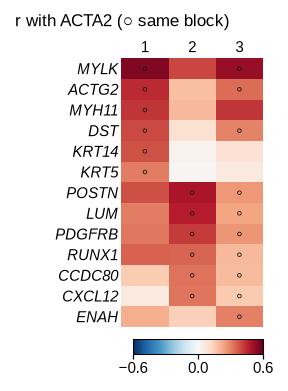

In [3]:
B_W, B_H = 52.0, 67.0


def panel_b(P):
    a = pd.read_csv(FULL / "acta2.csv")
    rows = []
    for k in NICHES:
        for g in a[(a.niche == k) & a.in_block].nlargest(6, "r").gene:
            if g not in rows:
                rows.append(g)
    r = a.pivot(index="gene", columns="niche", values="r").loc[rows, NICHES].to_numpy()
    inb = a.pivot(index="gene", columns="niche", values="in_block").loc[rows, NICHES].to_numpy().astype(bool)
    h = 3.0 + 3.5 * len(rows)
    ax = box(P, 10, 5, 38, h, left=13.0, bottom=0.5, right=1.0, top=2.5)
    ax.imshow(r, cmap=ps.DIVERGING, vmin=-ACTA2_LIM, vmax=ACTA2_LIM, aspect="auto", interpolation="nearest")
    yy, xx = np.nonzero(inb)
    ax.scatter(xx, yy, s=3, marker="o", fc="none", ec=ps.INK, lw=0.4)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows, fontstyle="italic")
    ax.set_xticks(range(len(NICHES)))
    ax.set_xticklabels([str(k + 1) for k in NICHES])
    ax.xaxis.tick_top()
    heat_axes(ax)
    hbar(P, 23, 5 + h + 1, 26, 7, ps.DIVERGING, -ACTA2_LIM, ACTA2_LIM, [-ACTA2_LIM, 0, ACTA2_LIM])
    text(P, 5, 0, "r with ACTA2 (○ same block)")


fig = ps.panel(B_W, B_H)
panel_b(At(fig))
ps.save_panel(fig, FIG, "B")

## C · Block programmes of the chosen niche, and the contrast niche in its order

figures/figS2_breast/panels/C.pdf/.png: 180 x 64 mm, 0.4 / 1.5 MB


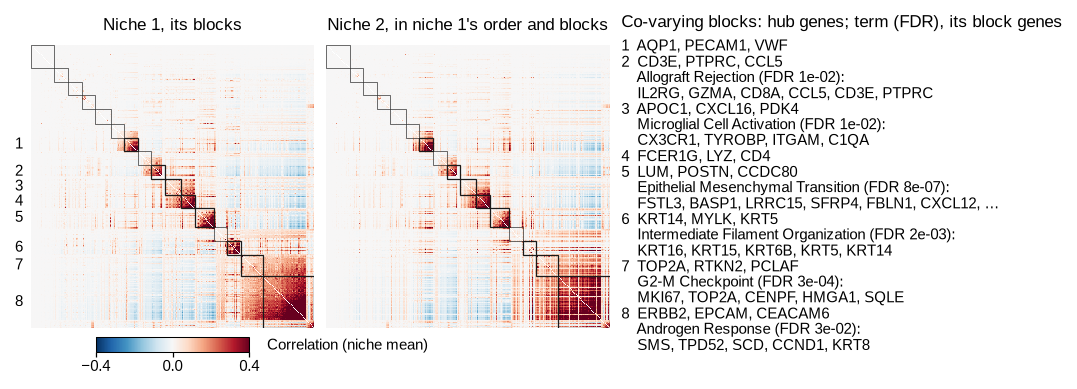

In [4]:
C_W, C_H = 180.0, 64.0
CX, CY, CW = 4.0, 7.0, 48.0  # main matrix: origin and side (mm)


def key_lines(main):
    lines = []
    for r in main.itertuples():
        if not r.covarying:
            continue
        line = f"{len(lines) + 1}  {', '.join(r.hubs.split())}"
        if r.enriched:
            term = re.sub(r"\s*\(GO:\d+\)", "", r.key_term)
            genes = r.key_genes.split()
            genes = ", ".join(genes[:6]) + (", …" if len(genes) > 6 else "")
            line += f"\n    {term} (FDR {r.key_fdr:.0e}):\n    {genes}"
        lines.append(line)
    return lines


def panel_c(P):
    perm = np.array(LAYOUT[str(MAIN)]["perm"])
    runs = LAYOUT[str(MAIN)]["blocks"]
    R_main = np.load(FULL / f"corr_niche{MAIN}.npy")
    R_c = np.load(FULL / f"corr_niche{CONTRAST}.npy")
    pos_c = np.empty(len(perm), int)
    pos_c[np.array(LAYOUT[str(CONTRAST)]["perm"])] = np.arange(len(perm))
    R_c = R_c[np.ix_(pos_c[perm], pos_c[perm])]  # contrast niche in the main niche's gene order
    main = blocks[blocks.niche == MAIN].sort_values("block")
    cov = main.set_index("block")
    for x, R in ((CX, R_main), (CX + CW + 2, R_c)):
        ax = box(P, x, CY, CW, CW)
        R = R.copy()
        np.fill_diagonal(R, np.nan)
        ax.imshow(R, cmap=ps.DIVERGING, vmin=-CORR_LIM, vmax=CORR_LIM, interpolation="nearest")
        for b, (s, e) in enumerate(runs):
            lw = 0.6 if cov.loc[b, "covarying"] else 0.3
            ax.add_patch(Rectangle((s - 0.5, s - 0.5), e - s, e - s, fill=False, ec=ps.INK, lw=lw))
        ax.set_xlim(-0.5, len(perm) - 0.5)
        ax.set_ylim(len(perm) - 0.5, -0.5)
        ax.axis("off")
    text(P, CX, CY - 4.5, f"Niche {MAIN + 1}, its blocks", ha="center", w=CW)
    text(P, CX + CW + 2, CY - 4.5, f"Niche {CONTRAST + 1}, in niche {MAIN + 1}'s order and blocks", ha="center", w=CW)
    hbar(P, 13, CY + CW + 1, 30, 7, ps.DIVERGING, -CORR_LIM, CORR_LIM, [-CORR_LIM, 0, CORR_LIM])
    text(P, 44, CY + CW + 1.8, "Correlation (niche mean)", size=ps.TICK_PT)
    p = len(GENES)
    num = 0
    for r in main.itertuples():
        if r.covarying:
            num += 1
            text(P, 0, CY + (r.start + r.end) / 2 / p * CW - 1.2, str(num), size=ps.TICK_PT, ha="center", w=4)
    text(P, 104, CY - 5, "Co-varying blocks: hub genes; term (FDR), its block genes")
    text(P, 104, CY - 1, "\n".join(key_lines(main)), size=ps.TICK_PT, linespacing=1.15)


fig = ps.panel(C_W, C_H)
panel_c(At(fig))
ps.save_panel(fig, FIG, "C")

## The figure

figures/figS2_breast/figS2_breast.pdf/.png: 180 x 131 mm, 1.7 / 3.4 MB


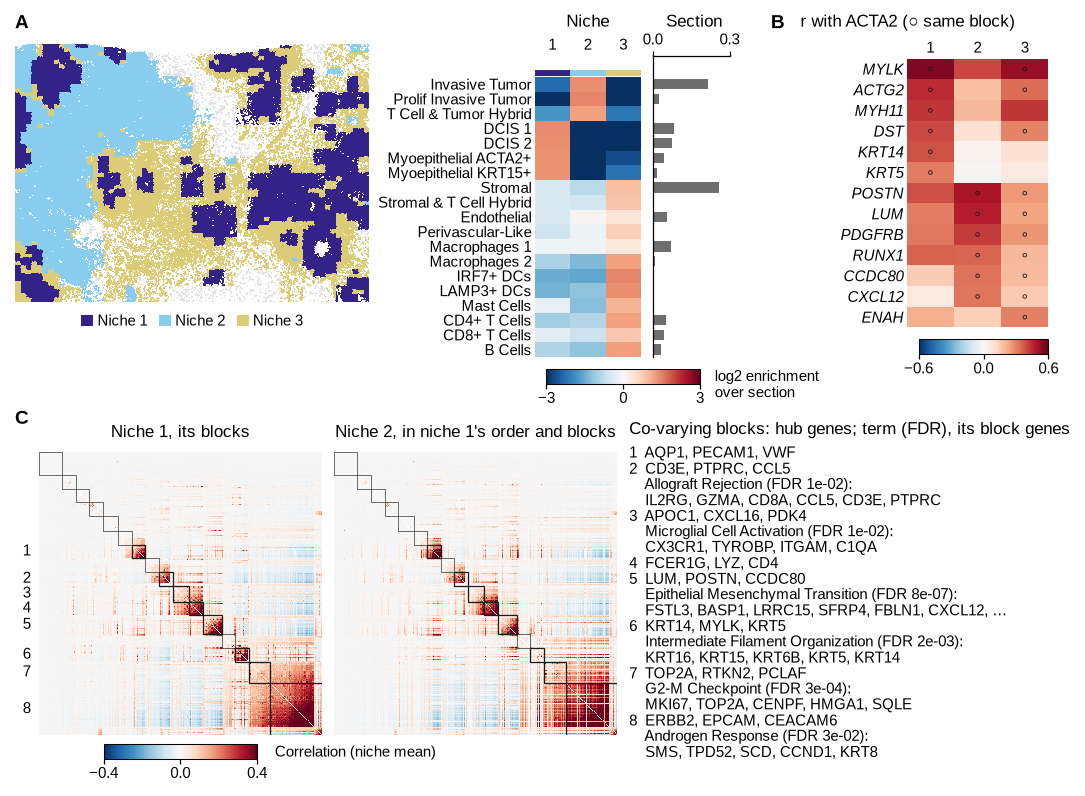

In [5]:
page = ps.page(180, 131)
panel_a(At(ps.place(page, "A", 0, 0, A_W, A_H)))
panel_b(At(ps.place(page, "B", 128, 0, B_W, B_H)))
panel_c(At(ps.place(page, "C", 0, 67, C_W, C_H)))
ps.save_figure(page, FIG)